In [11]:
!pip install shap xgboost -q

In [12]:
import pandas as pd
import numpy as np

df = pd.read_csv('https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv')
print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [13]:
neg, pos = df['Class'].value_counts()
print(f'Normais: {neg} ({neg/len(df)*100:.3f}%)')
print(f'Fraudes: {pos} ({pos/len(df)*100:.3f}%)')

Normais: 284315 (99.827%)
Fraudes: 492 (0.173%)


In [14]:
df['Log_Amount'] = np.log(df['Amount'] + 0.001)
df = df.drop('Time', axis=1)

In [15]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

X = df.drop('Class', axis=1)
y = df['Class']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, stratify=y, random_state=42
)

In [16]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
log_reg.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [17]:
from sklearn.metrics import classification_report, roc_auc_score

y_pred = log_reg.predict(X_test)
print(classification_report(y_test, y_pred))
print('ROC AUC:', roc_auc_score(y_test, log_reg.predict_proba(X_test)[:, 1]))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     85295
           1       0.06      0.87      0.12       148

    accuracy                           0.98     85443
   macro avg       0.53      0.92      0.55     85443
weighted avg       1.00      0.98      0.99     85443

ROC AUC: 0.9699324126283503


In [18]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.97      0.70      0.82       148

    accuracy                           1.00     85443
   macro avg       0.99      0.85      0.91     85443
weighted avg       1.00      1.00      1.00     85443



In [19]:
from xgboost import XGBClassifier

scale_pos_weight = neg / pos
xgb = XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss')
xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)
print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.90      0.78      0.84       148

    accuracy                           1.00     85443
   macro avg       0.95      0.89      0.92     85443
weighted avg       1.00      1.00      1.00     85443



In [20]:
probs_logreg = log_reg.predict_proba(X_test)[:, 1]
y_pred_ajustado = (probs_logreg >= 0.7).astype(int)
print(classification_report(y_test, y_pred_ajustado))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99     85295
           1       0.12      0.85      0.22       148

    accuracy                           0.99     85443
   macro avg       0.56      0.92      0.60     85443
weighted avg       1.00      0.99      0.99     85443



In [21]:
probs_xgb = xgb.predict_proba(X_test)[:, 1]

for t in [0.2, 0.3, 0.4, 0.5]:
    y_pred_t = (probs_xgb >= t).astype(int)
    print(f'--- Limiar {t} ---')
    print(classification_report(y_test, y_pred_t))

--- Limiar 0.2 ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.84      0.80      0.82       148

    accuracy                           1.00     85443
   macro avg       0.92      0.90      0.91     85443
weighted avg       1.00      1.00      1.00     85443

--- Limiar 0.3 ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.86      0.78      0.82       148

    accuracy                           1.00     85443
   macro avg       0.93      0.89      0.91     85443
weighted avg       1.00      1.00      1.00     85443

--- Limiar 0.4 ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.89      0.78      0.83       148

    accuracy                           1.00     85443
   macro avg       0.94      0.89      0.92     85443
weighted avg     

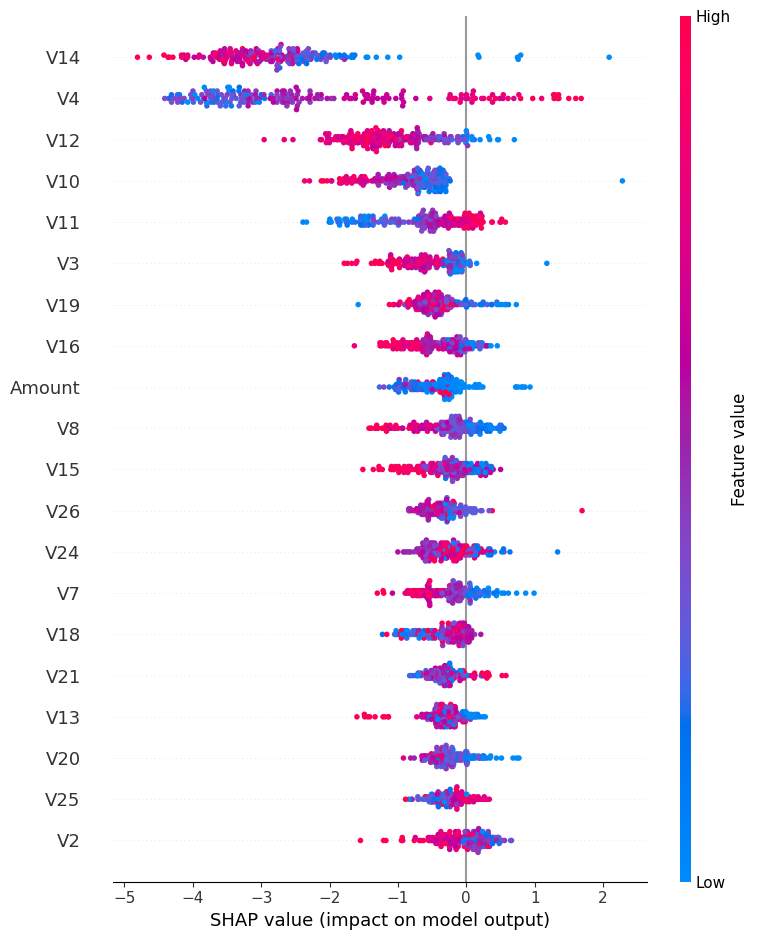

In [22]:
import shap

explainer = shap.TreeExplainer(xgb, feature_perturbation='tree_path_dependent')
shap_values = explainer.shap_values(X_test[:200])

shap.summary_plot(shap_values, X_test[:200], feature_names=X.columns)

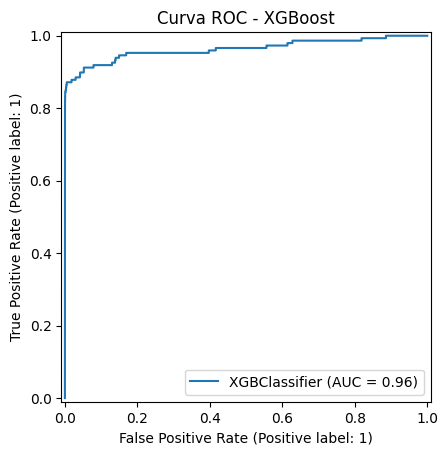

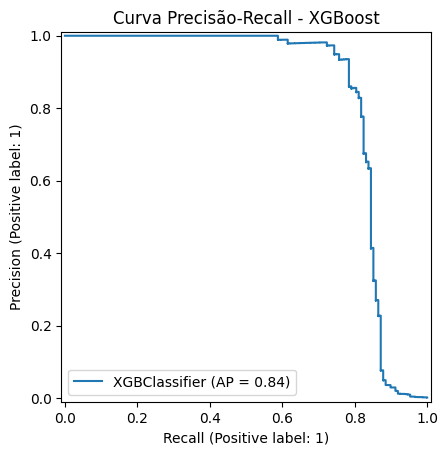

In [23]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

RocCurveDisplay.from_estimator(xgb, X_test, y_test)
plt.title('Curva ROC - XGBoost')
plt.show()

PrecisionRecallDisplay.from_estimator(xgb, X_test, y_test)
plt.title('Curva Precisão-Recall - XGBoost')
plt.show()